In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


# Rossmann Sales Forecasting

## 1. Data Understanding

The goal of this project is to forecast future Rossmann store sales using historical sales data and relevant business features.

In [3]:
train = pd.read_csv("../data/train.csv")
store = pd.read_csv("../data/store.csv")
test = pd.read_csv("../data/test.csv")

C:\Users\radhe\AppData\Local\Temp\ipykernel_14796\629511070.py:1: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("../data/train.csv")


In [4]:
print("Train shape:", train.shape)
print("Store shape:", store.shape)
print("Test shape:", test.shape)

Train shape: (1017209, 9)
Store shape: (1115, 10)
Test shape: (41088, 8)


In [5]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [6]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [7]:
test.head()

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [8]:
print("TRAIN DATA")
print("-" * 40)
print(f"Rows: {train.shape[0]:,}")
print(f"Columns: {train.shape[1]}")

print("\nSTORE DATA")
print("-" * 40)
print(f"Rows: {store.shape[0]:,}")
print(f"Columns: {store.shape[1]}")

print("\nTEST DATA")
print("-" * 40)
print(f"Rows: {test.shape[0]:,}")
print(f"Columns: {test.shape[1]}")

TRAIN DATA
----------------------------------------
Rows: 1,017,209
Columns: 9

STORE DATA
----------------------------------------
Rows: 1,115
Columns: 10

TEST DATA
----------------------------------------
Rows: 41,088
Columns: 8


In [9]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 69.8+ MB


In [10]:
store.info()

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 87.2 KB


In [11]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             41088 non-null  int64  
 1   Store          41088 non-null  int64  
 2   DayOfWeek      41088 non-null  int64  
 3   Date           41088 non-null  str    
 4   Open           41077 non-null  float64
 5   Promo          41088 non-null  int64  
 6   StateHoliday   41088 non-null  str    
 7   SchoolHoliday  41088 non-null  int64  
dtypes: float64(1), int64(5), str(2)
memory usage: 2.5 MB


In [12]:
print("Train columns:")
print(train.columns.tolist())

print("\nStore columns:")
print(store.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

Train columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Store columns:
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

Test columns:
['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


In [13]:
train["Sales"].describe()

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

In [14]:
train["Sales"].value_counts().head(10)

Sales
0       172871
5674       215
5558       197
5483       196
6049       195
6214       195
5723       194
5449       192
5489       191
5140       191
Name: count, dtype: int64

In [15]:
print("Earliest date:", train["Date"].min())
print("Latest date:", train["Date"].max())

Earliest date: 2013-01-01
Latest date: 2015-07-31


In [16]:
print("Number of stores:", train["Store"].nunique())

Number of stores: 1115


In [17]:
print("Number of store records:", store["Store"].nunique())

Number of store records: 1115


In [18]:
train.groupby("Store")["Sales"].count().describe()

count    1115.000000
mean      912.295067
std        67.729422
min       758.000000
25%       942.000000
50%       942.000000
75%       942.000000
max       942.000000
Name: Sales, dtype: float64

In [19]:
train["Open"].value_counts()

Open
1    844392
0    172817
Name: count, dtype: int64

In [20]:
train.groupby("Open")["Sales"].mean()

Open
0       0.000000
1    6955.514291
Name: Sales, dtype: float64

In [21]:
train["Promo"].value_counts()

Promo
0    629129
1    388080
Name: count, dtype: int64

In [22]:
train.groupby("Promo")["Sales"].mean()

Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64

In [23]:
print("SALES SUMMARY")
print(train["Sales"].describe())

SALES SUMMARY
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64


In [24]:
print("\nOPEN STATUS")
print(train["Open"].value_counts())


OPEN STATUS
Open
1    844392
0    172817
Name: count, dtype: int64


In [25]:
print("\nAVERAGE SALES BY OPEN STATUS")
print(train.groupby("Open")["Sales"].mean())


AVERAGE SALES BY OPEN STATUS
Open
0       0.000000
1    6955.514291
Name: Sales, dtype: float64


In [26]:
print("\nPROMOTION STATUS")
print(train["Promo"].value_counts())


PROMOTION STATUS
Promo
0    629129
1    388080
Name: count, dtype: int64


In [27]:
print("\nAVERAGE SALES BY PROMOTION")
print(train.groupby("Promo")["Sales"].mean())


AVERAGE SALES BY PROMOTION
Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64


In [28]:
print("\nZERO SALES")
print((train["Sales"] == 0).sum())


ZERO SALES
172871


In [29]:
print("\nZERO SALES BY OPEN STATUS")
print(
    train.groupby("Open")["Sales"]
    .apply(lambda x: (x == 0).sum())
)


ZERO SALES BY OPEN STATUS


Open
0    172817
1        54
Name: Sales, dtype: int64


In [30]:
df = train.copy()

In [31]:
df.shape

(1017209, 9)

In [32]:
df["Date"] = pd.to_datetime(df["Date"])

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), object(1)
memory usage: 69.8+ MB


In [34]:
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

In [35]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,2,2013-01-01,0,0,0,0,a,1
1,1,3,2013-01-02,5530,668,1,0,0,1
2,1,4,2013-01-03,4327,578,1,0,0,1
3,1,5,2013-01-04,4486,619,1,0,0,1
4,1,6,2013-01-05,4997,635,1,0,0,1


In [36]:
df.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [37]:
missing = df.isnull().sum()

missing_percentage = (missing / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage
})

missing_summary

,Missing Values,Missing Percentage
Store,0,0.0
DayOfWeek,0,0.0
Date,0,0.0
Sales,0,0.0
Customers,0,0.0
Open,0,0.0
Promo,0,0.0
StateHoliday,0,0.0
SchoolHoliday,0,0.0


In [38]:
df.duplicated().sum()

np.int64(0)

In [39]:
duplicate_store_dates = df.duplicated(
    subset=["Store", "Date"]
).sum()

print("Duplicate Store-Date combinations:", duplicate_store_dates)

Duplicate Store-Date combinations: 0


In [40]:
print("Unique dates:", df["Date"].nunique())
print("Expected date range:")
print(df["Date"].min())
print(df["Date"].max())

Unique dates: 942
Expected date range:
2013-01-01 00:00:00
2015-07-31 00:00:00


In [41]:
date_range = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="D"
)

print("Expected calendar days:", len(date_range))
print("Actual dates:", df["Date"].nunique())

Expected calendar days: 942
Actual dates: 942


In [42]:
store_date_summary = df.groupby("Store")["Date"].agg(
    ["min", "max", "count"]
)

store_date_summary.head()

,min,max,count
Store,,,
1,2013-01-01,2015-07-31,942
2,2013-01-01,2015-07-31,942
3,2013-01-01,2015-07-31,942
4,2013-01-01,2015-07-31,942
5,2013-01-01,2015-07-31,942


In [43]:
store_date_summary["count"].describe()

count    1115.000000
mean      912.295067
std        67.729422
min       758.000000
25%       942.000000
50%       942.000000
75%       942.000000
max       942.000000
Name: count, dtype: float64

In [44]:
df["Open"].value_counts()
df.groupby("Open")["Sales"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
Open,,,,
0,172817,0.000000,0,0
1,844392,6955.514291,0,41551


In [45]:
print("Negative sales:", (df["Sales"] < 0).sum())
print("Negative customers:", (df["Customers"] < 0).sum())
print("Open values:", df["Open"].unique())
print("Promo values:", df["Promo"].unique())
print("DayOfWeek values:", sorted(df["DayOfWeek"].unique()))

Negative sales: 0
Negative customers: 0
Open values: [0 1]
Promo values: [0 1]
DayOfWeek values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


In [46]:
store.isnull().sum()

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

In [47]:
store_missing = pd.DataFrame({
    "Missing Values": store.isnull().sum(),
    "Missing Percentage": store.isnull().mean() * 100
})

store_missing.sort_values(
    "Missing Values",
    ascending=False
)

,Missing Values,Missing Percentage
PromoInterval,544,48.789238
Promo2SinceYear,544,48.789238
Promo2SinceWeek,544,48.789238
CompetitionOpenSinceYear,354,31.748879
CompetitionOpenSinceMonth,354,31.748879
CompetitionDistance,3,0.269058
StoreType,0,0.000000
Store,0,0.000000
Assortment,0,0.000000
Promo2,0,0.000000


In [48]:
store[store["CompetitionDistance"].isnull()]

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
290,291,d,a,NaN,NaN,NaN,0,NaN,NaN,NaN
621,622,a,c,NaN,NaN,NaN,0,NaN,NaN,NaN
878,879,d,a,NaN,NaN,NaN,1,5.0,2013.0,"Feb,May,Aug,Nov"


In [49]:
df.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [50]:
df.duplicated(subset=["Store", "Date"]).sum()

np.int64(0)

In [51]:
store_date_summary["count"].describe()

count    1115.000000
mean      912.295067
std        67.729422
min       758.000000
25%       942.000000
50%       942.000000
75%       942.000000
max       942.000000
Name: count, dtype: float64

In [52]:
print("Negative sales:", (df["Sales"] < 0).sum())
print("Negative customers:", (df["Customers"] < 0).sum())

Negative sales: 0
Negative customers: 0


In [53]:
store_missing.sort_values(
    "Missing Values",
    ascending=False
)

,Missing Values,Missing Percentage
PromoInterval,544,48.789238
Promo2SinceYear,544,48.789238
Promo2SinceWeek,544,48.789238
CompetitionOpenSinceYear,354,31.748879
CompetitionOpenSinceMonth,354,31.748879
CompetitionDistance,3,0.269058
StoreType,0,0.000000
Store,0,0.000000
Assortment,0,0.000000
Promo2,0,0.000000


In [54]:
daily_sales = (
    df.groupby("Date", as_index=False)
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Customers=("Customers", "sum"),
          Open_Stores=("Open", "sum")
      )
)

In [56]:
daily_sales.head()

,Date,Total_Sales,Total_Customers,Open_Stores
0,2013-01-01,97235,19491,17
1,2013-01-02,6949829,834075,1111
2,2013-01-03,6347820,761040,1109
3,2013-01-04,6638954,782137,1108
4,2013-01-05,5951593,687472,1107


In [57]:
daily_sales.shape

(942, 4)

In [58]:
daily_sales = daily_sales.sort_values("Date").reset_index(drop=True)

In [59]:
daily_sales.head()

,Date,Total_Sales,Total_Customers,Open_Stores
0,2013-01-01,97235,19491,17
1,2013-01-02,6949829,834075,1111
2,2013-01-03,6347820,761040,1109
3,2013-01-04,6638954,782137,1108
4,2013-01-05,5951593,687472,1107


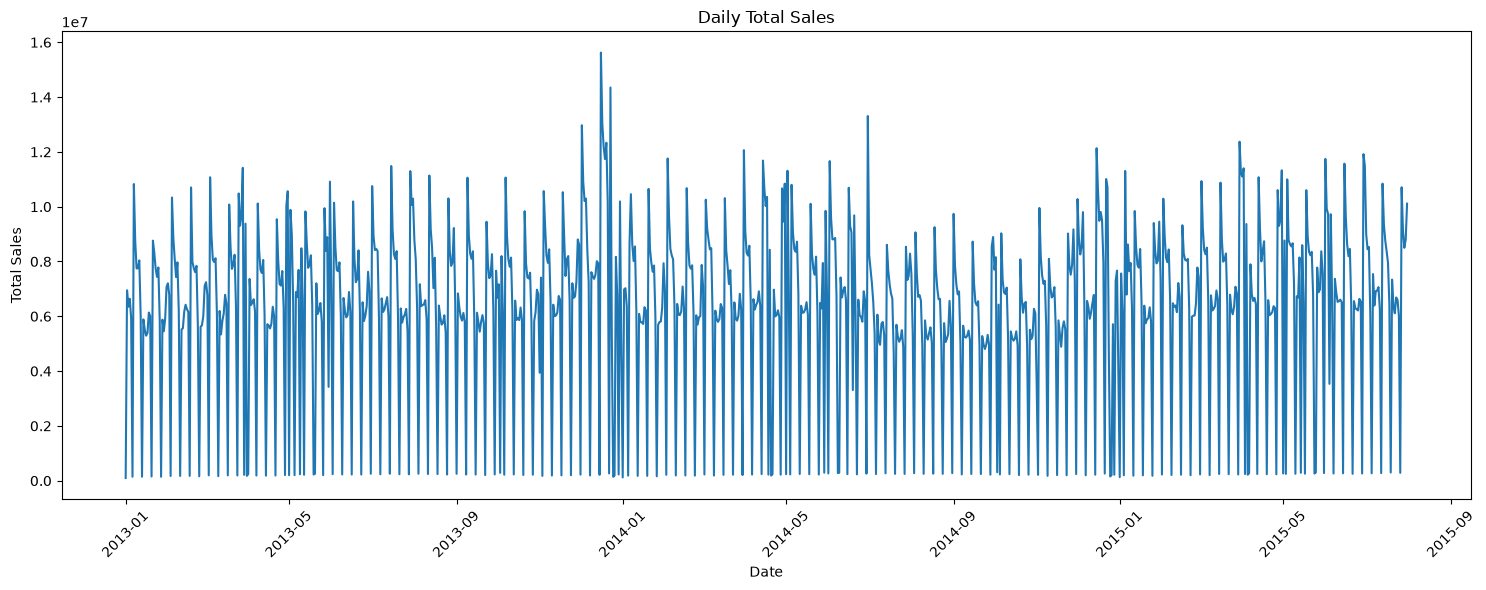

In [60]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["Date"],
    daily_sales["Total_Sales"]
)

plt.title("Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [61]:
daily_sales["Rolling_30"] = (
    daily_sales["Total_Sales"]
    .rolling(window=30)
    .mean()
)

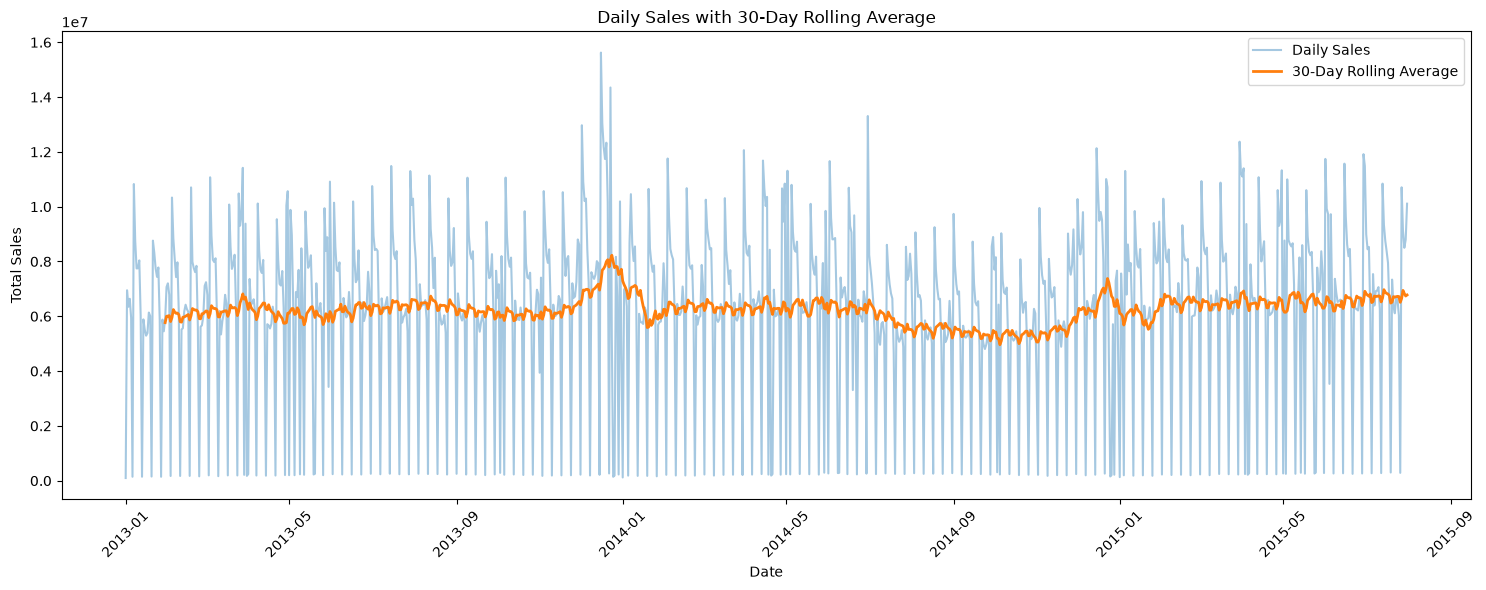

In [62]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["Date"],
    daily_sales["Total_Sales"],
    label="Daily Sales",
    alpha=0.4
)

plt.plot(
    daily_sales["Date"],
    daily_sales["Rolling_30"],
    label="30-Day Rolling Average",
    linewidth=2
)

plt.title("Daily Sales with 30-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
monthly_sales = (
    daily_sales
    .set_index("Date")["Total_Sales"]
    .resample("ME")
    .sum()
    .reset_index()
)

In [65]:
monthly_sales.head()

,Date,Total_Sales
0,2013-01-31,180132207
1,2013-02-28,171534275
2,2013-03-31,201180369
3,2013-04-30,183431432
4,2013-05-31,185411063


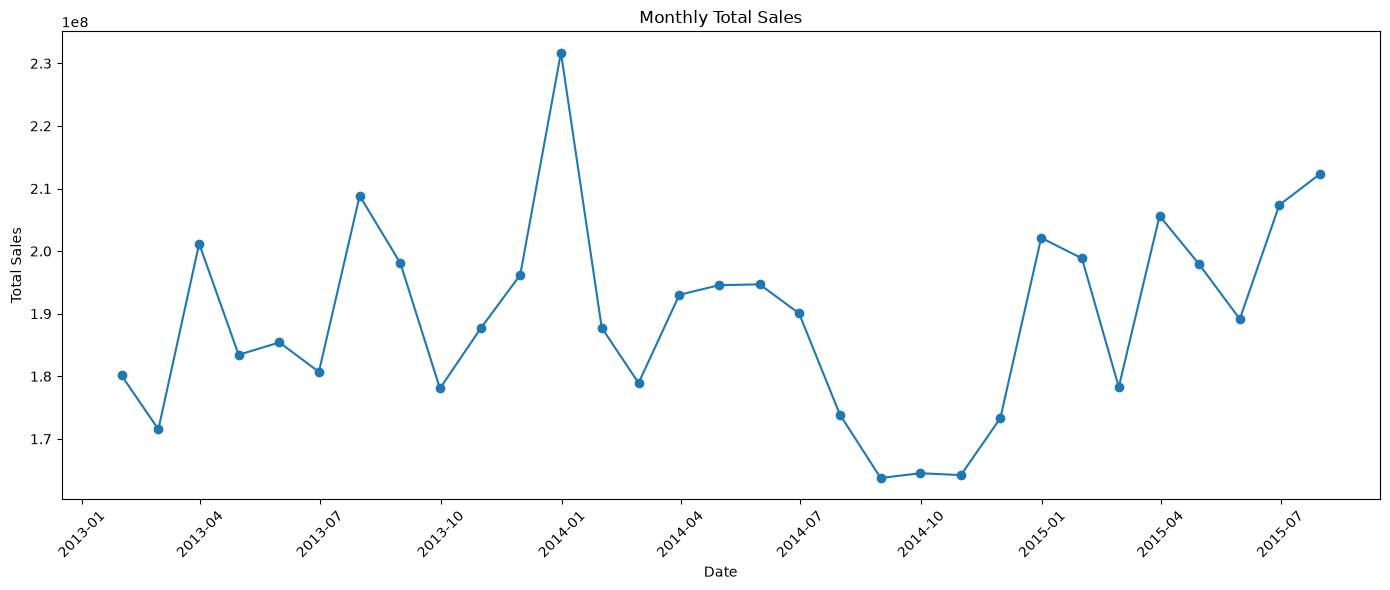

In [66]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Date"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Total Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
monthly_sales["Year"] = monthly_sales["Date"].dt.year
monthly_sales["Month"] = monthly_sales["Date"].dt.month

In [68]:
monthly_pattern = (
    monthly_sales
    .groupby("Month")["Total_Sales"]
    .mean()
)

monthly_pattern

Month
1     1.889096e+08
2     1.762448e+08
3     1.999440e+08
4     1.919651e+08
5     1.897494e+08
6     1.927043e+08
7     1.983531e+08
8     1.808956e+08
9     1.712851e+08
10    1.759394e+08
11    1.847494e+08
12    2.169156e+08
Name: Total_Sales, dtype: float64

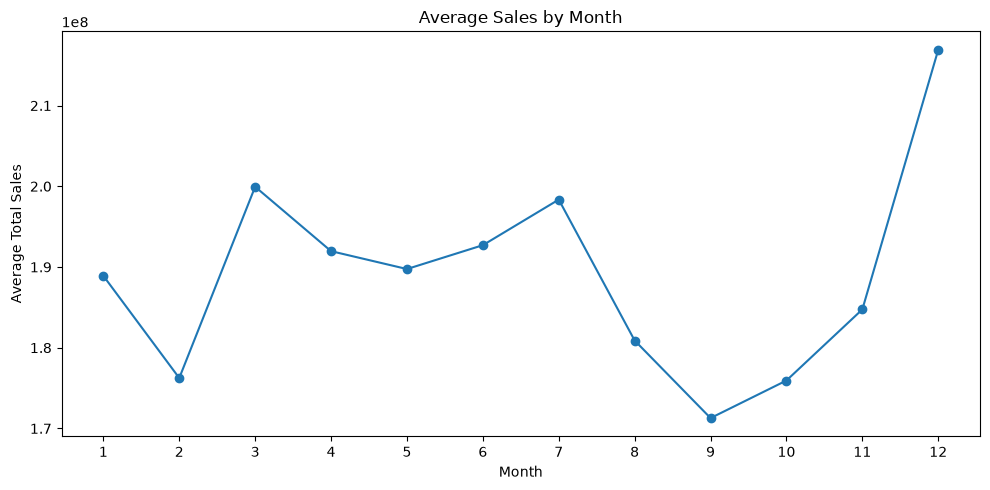

In [69]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern.values,
    marker="o"
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Total Sales")

plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [70]:
weekday_sales = (
    df.groupby("DayOfWeek")["Sales"]
      .mean()
)

weekday_sales

DayOfWeek
1    7809.044510
2    7005.244467
3    6555.884138
4    6247.575913
5    6723.274305
6    5847.562599
7     204.183189
Name: Sales, dtype: float64

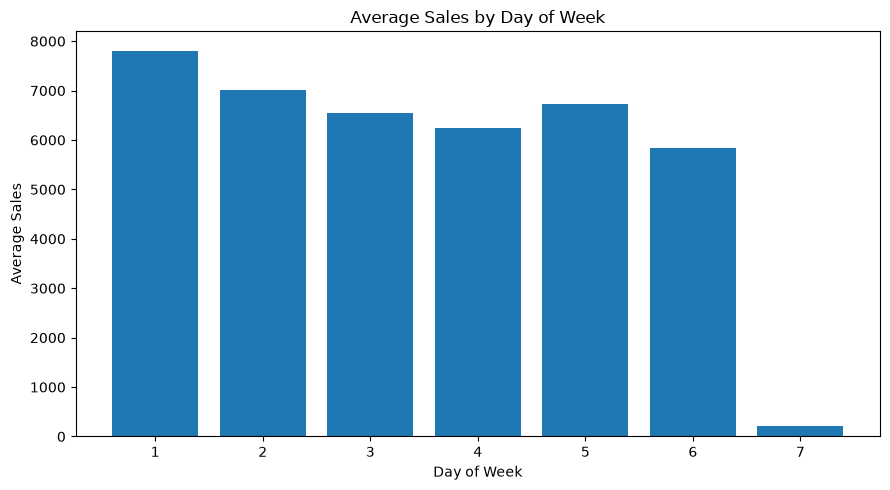

In [71]:
plt.figure(figsize=(9, 5))

plt.bar(
    weekday_sales.index,
    weekday_sales.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")

plt.xticks(range(1, 8))
plt.tight_layout()
plt.show()

In [72]:
weekday_summary = (
    df.groupby("DayOfWeek")
      .agg(
          Average_Sales=("Sales", "mean"),
          Median_Sales=("Sales", "median"),
          Total_Sales=("Sales", "sum")
      )
)

weekday_summary

,Average_Sales,Median_Sales,Total_Sales
DayOfWeek,,,
1,7809.044510,7310.0,1130203012
2,7005.244467,6463.0,1020411930
3,6555.884138,6133.0,954962863
4,6247.575913,6020.0,911177709
5,6723.274305,6434.0,980555941
6,5847.562599,5410.0,846317735
7,204.183189,0.0,29551433


In [73]:
daily_sales.nlargest(
    10,
    "Total_Sales"
)

,Date,Total_Sales,Total_Customers,Open_Stores,Rolling_30
349,2013-12-16,15623548,1340280,1115,7.255010e+06
356,2013-12-23,14350056,1518600,1115,8.059329e+06
545,2014-06-30,13308602,1189439,1112,6.334902e+06
350,2013-12-17,13053993,1198877,1115,7.683656e+06
335,2013-12-02,12972440,1199202,1115,6.600413e+06
818,2015-03-30,12371453,1064757,1115,6.480292e+06
353,2013-12-20,12334496,1219287,1115,7.995903e+06
351,2013-12-18,12189674,1158335,1115,7.739024e+06
713,2014-12-15,12133381,1054956,935,6.180582e+06
454,2014-03-31,12062933,1125153,1114,6.197697e+06


In [74]:
daily_sales.nsmallest(
    10,
    "Total_Sales"
)

,Date,Total_Sales,Total_Customers,Open_Stores,Rolling_30
0,2013-01-01,97235,19491,17,NaN
365,2014-01-01,118108,21925,18,7.287873e+06
730,2015-01-01,130162,23049,18,6.104332e+06
358,2013-12-25,142585,24022,17,7.991745e+06
26,2013-01-27,142848,27286,20,NaN
5,2013-01-06,143904,26387,19,NaN
12,2013-01-13,144052,27044,18,NaN
19,2013-01-20,151600,28040,19,NaN
723,2014-12-25,155386,24451,16,6.974678e+06
54,2013-02-24,159057,30107,20,5.914384e+06


In [75]:
daily_sales["Year"] = daily_sales["Date"].dt.year
daily_sales["Month"] = daily_sales["Date"].dt.month
daily_sales["DayOfWeek"] = daily_sales["Date"].dt.dayofweek

In [76]:
year_month_sales = (
    df.assign(
        Year=df["Date"].dt.year,
        Month=df["Date"].dt.month
    )
    .groupby(["Year", "Month"])["Sales"]
    .sum()
    .reset_index()
)

In [77]:
year_month_sales.head(15)

,Year,Month,Sales
0,2013,1,180132207
1,2013,2,171534275
2,2013,3,201180369
3,2013,4,183431432
4,2013,5,185411063
5,2013,6,180702351
6,2013,7,208843882
7,2013,8,198042727
8,2013,9,178053963
9,2013,10,187662330


In [78]:
year_month_pivot = year_month_sales.pivot(
    index="Month",
    columns="Year",
    values="Sales"
)

year_month_pivot

Year,2013,2014,2015
Month,,,
1,180132207.0,187752787.0,198843730.0
2,171534275.0,178924677.0,178275458.0
3,201180369.0,193019854.0,205631683.0
4,183431432.0,194544977.0,197918886.0
5,185411063.0,194693257.0,189143897.0
6,180702351.0,190047051.0,207363373.0
7,208843882.0,173892707.0,212322616.0
8,198042727.0,163748475.0,NaN
9,178053963.0,164516168.0,NaN


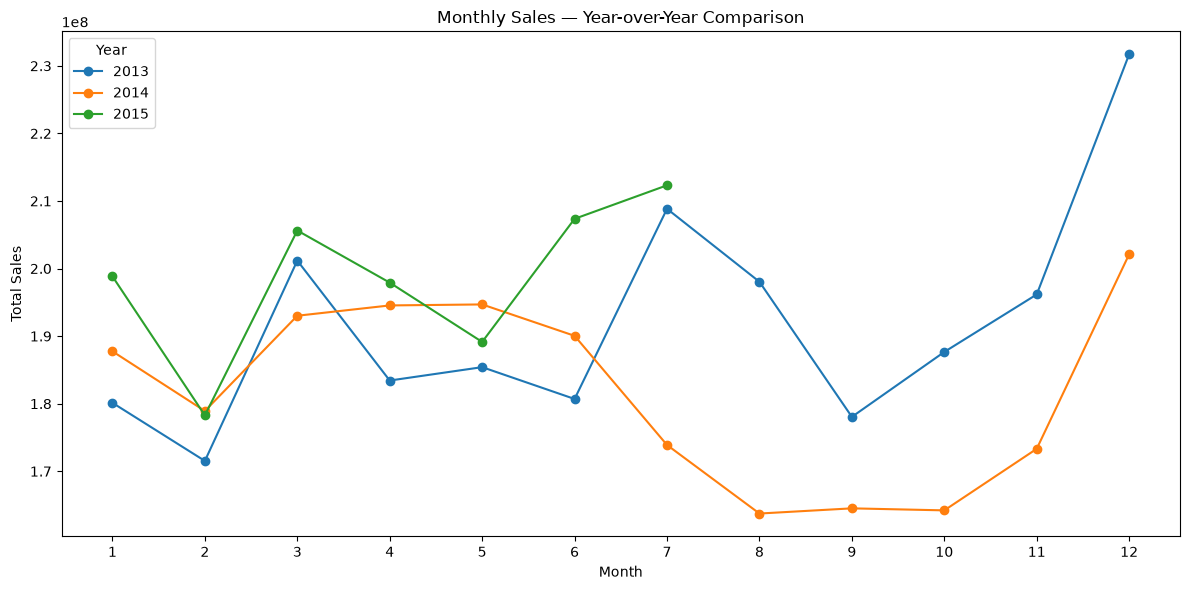

In [79]:
plt.figure(figsize=(12, 6))

for year in year_month_pivot.columns:
    plt.plot(
        year_month_pivot.index,
        year_month_pivot[year],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Sales — Year-over-Year Comparison")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(range(1, 13))
plt.legend(title="Year")

plt.tight_layout()
plt.show()

In [80]:
daily_sales["DayOfWeek"]

0      1
1      2
2      3
3      4
4      5
      ..
937    0
938    1
939    2
940    3
941    4
Name: DayOfWeek, Length: 942, dtype: int32

In [81]:
daily_sales["DayOfWeek"]

0      1
1      2
2      3
3      4
4      5
      ..
937    0
938    1
939    2
940    3
941    4
Name: DayOfWeek, Length: 942, dtype: int32

In [83]:
daily_sales["Day_Name"] = daily_sales["Date"].dt.day_name()

In [84]:
daily_sales[["Date", "Day_Name"]].head(10)

,Date,Day_Name
0,2013-01-01,Tuesday
1,2013-01-02,Wednesday
2,2013-01-03,Thursday
3,2013-01-04,Friday
4,2013-01-05,Saturday
5,2013-01-06,Sunday
6,2013-01-07,Monday
7,2013-01-08,Tuesday
8,2013-01-09,Wednesday
9,2013-01-10,Thursday


In [85]:
weekly_pattern = (
    daily_sales
    .groupby("Day_Name")["Total_Sales"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

weekly_pattern

Day_Name
Monday       8.434351e+06
Tuesday      7.558607e+06
Wednesday    7.073799e+06
Thursday     6.749465e+06
Friday       7.263377e+06
Saturday     6.315804e+06
Sunday       2.205331e+05
Name: Total_Sales, dtype: float64

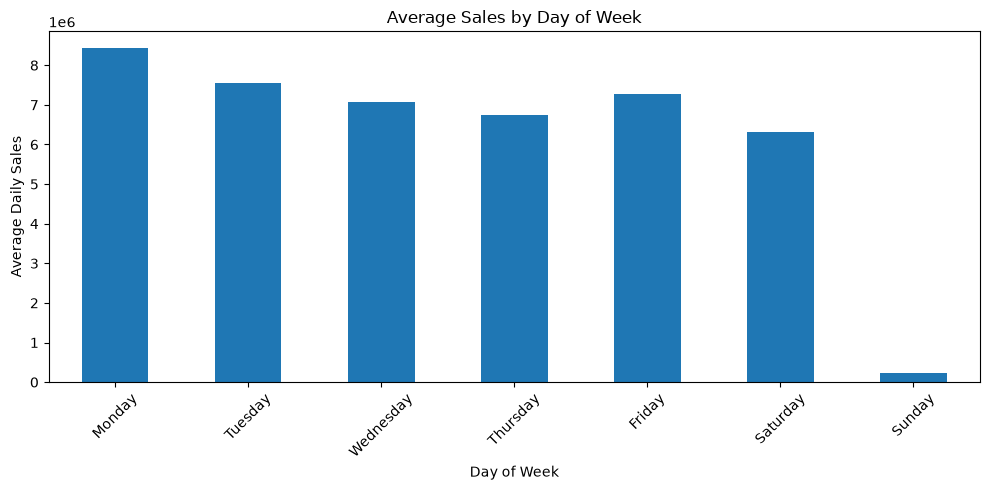

In [86]:
plt.figure(figsize=(10, 5))

weekly_pattern.plot(kind="bar")

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [87]:
month_names = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly_pattern = (
    daily_sales
    .groupby(daily_sales["Date"].dt.month)["Total_Sales"]
    .mean()
)

monthly_pattern.index = month_names

monthly_pattern

January      6.093857e+06
February     6.294457e+06
March        6.449805e+06
April        6.398837e+06
May          6.120949e+06
June         6.423475e+06
July         6.398486e+06
August       5.835342e+06
September    5.709502e+06
October      5.675463e+06
November     6.158315e+06
December     6.997277e+06
Name: Total_Sales, dtype: float64

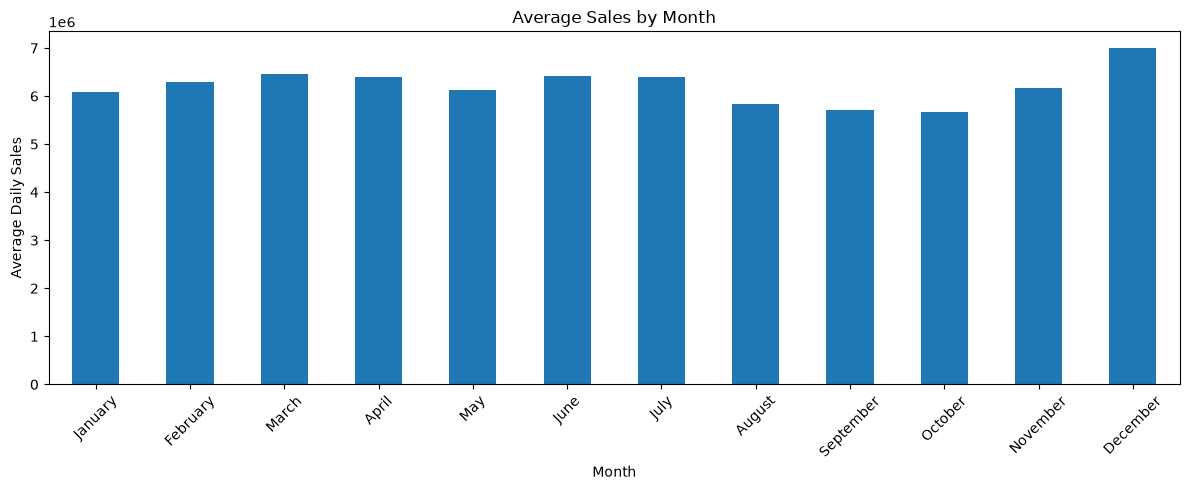

In [88]:
plt.figure(figsize=(12, 5))

monthly_pattern.plot(kind="bar")

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [89]:
yearly_sales = (
    df.groupby(df["Date"].dt.year)["Sales"]
      .sum()
)

yearly_sales

Date
2013    2302876084
2014    2180804896
2015    1389499643
Name: Sales, dtype: int64

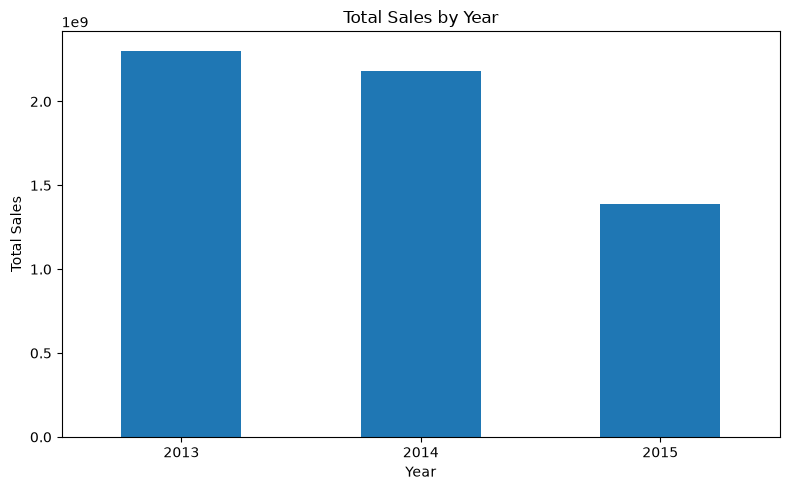

In [90]:
plt.figure(figsize=(8, 5))

yearly_sales.plot(kind="bar")

plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [91]:
yoy_growth = (
    year_month_pivot[2014] / year_month_pivot[2013] - 1
) * 100

yoy_growth

Month
1      4.230548
2      4.308411
3     -4.056318
4      6.058692
5      5.006278
6      5.171322
7    -16.735551
8    -17.316592
9     -7.603198
10   -12.493681
11   -11.644422
12   -12.770229
dtype: float64

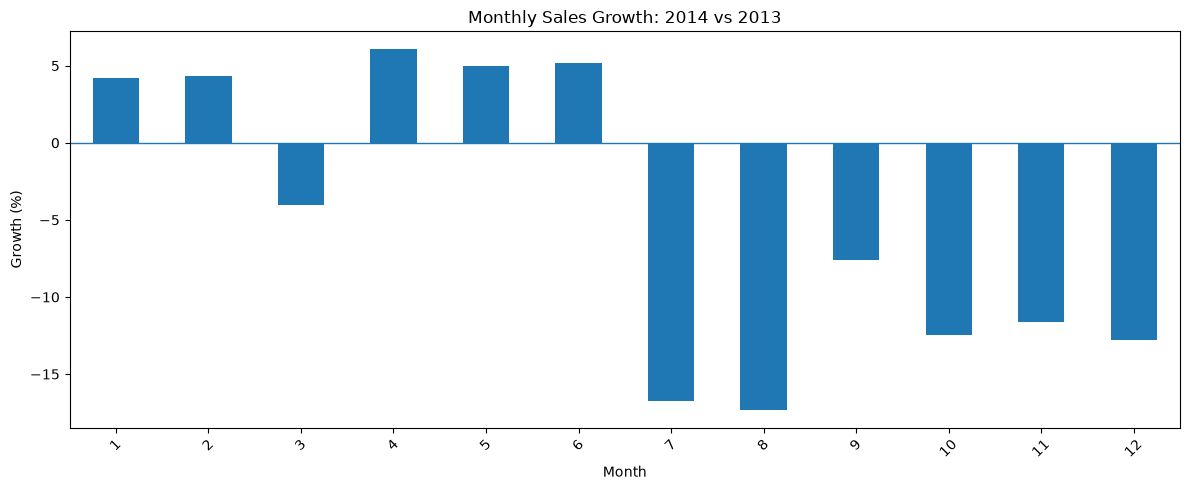

In [92]:
plt.figure(figsize=(12, 5))

yoy_growth.plot(kind="bar")

plt.axhline(0, linewidth=1)

plt.title("Monthly Sales Growth: 2014 vs 2013")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [93]:
store_sales = (
    df.groupby("Store")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

store_sales.head(10)

Store
262     19516842
817     17057867
562     16927322
1114    16202585
251     14896870
513     14252406
788     14082141
733     14067158
383     13489879
756     12911782
Name: Sales, dtype: int64

In [94]:
store_sales.tail(10)

Store
972    2402627
186    2353548
254    2341661
879    2340576
841    2318635
263    2306075
208    2302052
198    2268273
543    2179287
307    2114322
Name: Sales, dtype: int64

In [95]:
average_store_sales = (
    df.groupby("Store")["Sales"]
      .mean()
      .sort_values(ascending=False)
)

average_store_sales.head(10)

Store
262     20718.515924
817     18108.139066
562     17969.556263
1114    17200.196391
251     15814.087049
842     15242.114776
513     15129.942675
788     14949.194268
733     14933.288747
383     14320.466030
Name: Sales, dtype: float64

In [97]:
average_store_sales.tail(10)

Store
210    2641.309979
219    2591.467091
794    2553.475584
972    2550.559448
254    2485.839703
841    2461.395966
208    2443.791932
198    2407.933121
543    2313.468153
307    2244.503185
Name: Sales, dtype: float64

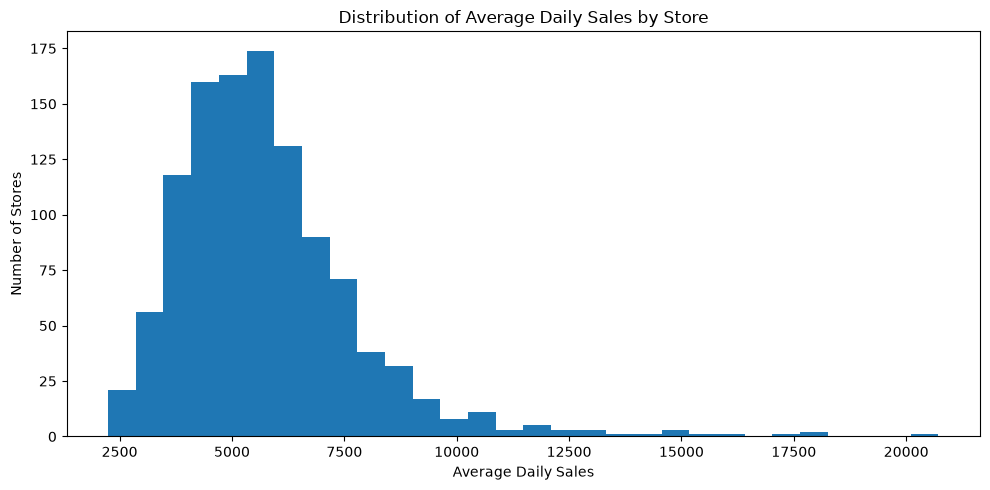

In [98]:
plt.figure(figsize=(10, 5))

plt.hist(average_store_sales, bins=30)

plt.title("Distribution of Average Daily Sales by Store")
plt.xlabel("Average Daily Sales")
plt.ylabel("Number of Stores")
plt.tight_layout()
plt.show()

In [99]:
median_store_sales = average_store_sales.median()

candidate_store = (
    (average_store_sales - median_store_sales)
    .abs()
    .idxmin()
)

print("Median average daily sales:", median_store_sales)
print("Candidate store:", candidate_store)
print(
    "Candidate average daily sales:",
    average_store_sales.loc[candidate_store]
)

Median average daily sales: 5459.185774946922
Candidate store: 551
Candidate average daily sales: 5459.185774946922


In [100]:
store_df = (
    df[df["Store"] == candidate_store]
      .copy()
      .sort_values("Date")
      .reset_index(drop=True)
)

store_df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,551,2,2013-01-01,0,0,0,0,a,1
1,551,3,2013-01-02,6576,1038,1,0,0,1
2,551,4,2013-01-03,5823,902,1,0,0,1
3,551,5,2013-01-04,5795,887,1,0,0,1
4,551,6,2013-01-05,4885,787,1,0,0,0


In [101]:
print("Rows:", len(store_df))
print("Start date:", store_df["Date"].min())
print("End date:", store_df["Date"].max())

Rows: 942
Start date: 2013-01-01 00:00:00
End date: 2015-07-31 00:00:00


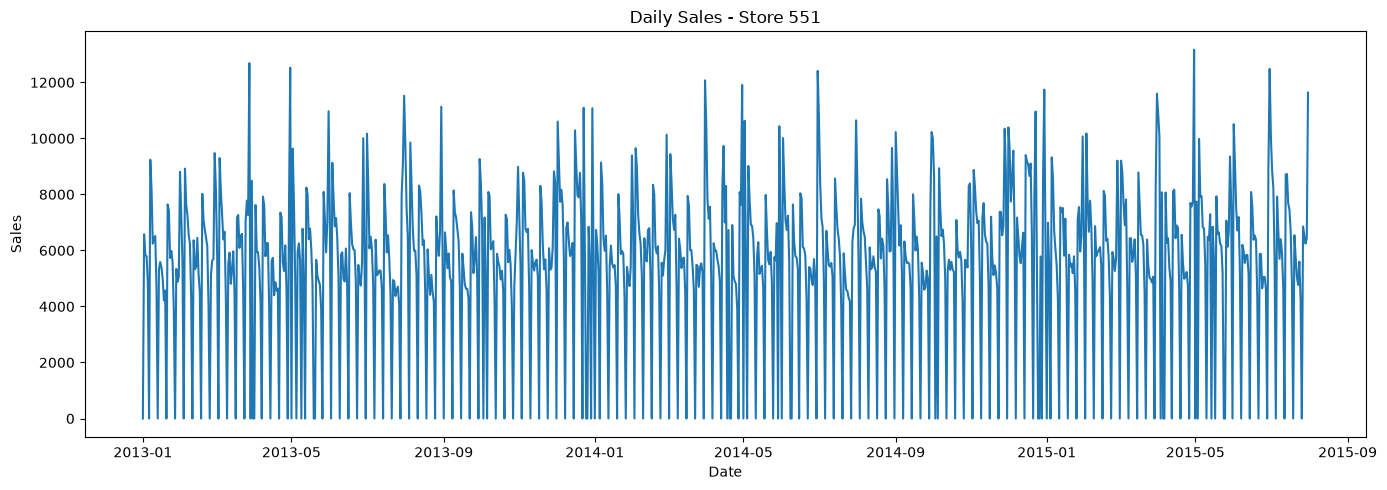

In [102]:
plt.figure(figsize=(14, 5))

plt.plot(
    store_df["Date"],
    store_df["Sales"]
)

plt.title(f"Daily Sales - Store {candidate_store}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [103]:
store_df["Rolling_30"] = (
    store_df["Sales"]
    .rolling(window=30)
    .mean()
)

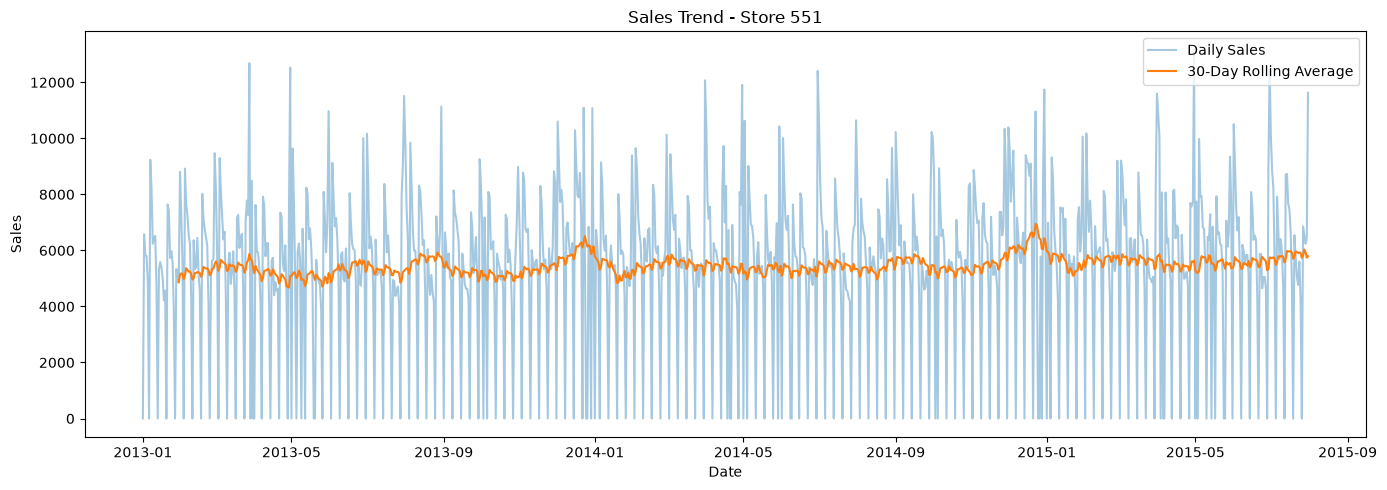

In [104]:
plt.figure(figsize=(14, 5))

plt.plot(
    store_df["Date"],
    store_df["Sales"],
    alpha=0.4,
    label="Daily Sales"
)

plt.plot(
    store_df["Date"],
    store_df["Rolling_30"],
    label="30-Day Rolling Average"
)

plt.title(f"Sales Trend - Store {candidate_store}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [106]:
store_df["Open"].value_counts()
store_df.groupby("Open")["Sales"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
Open,,,,
0,158,0.000000,0,0
1,784,6559.378827,3816,13163


In [107]:
store_df[store_df["Open"] == 0]["Sales"].value_counts().head()

Sales
0    158
Name: count, dtype: int64

In [108]:
store_df["Open"].value_counts()

Open
1    784
0    158
Name: count, dtype: int64

In [109]:
store_df.groupby("Open")["Sales"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
Open,,,,
0,158,0.000000,0,0
1,784,6559.378827,3816,13163


In [110]:
store_df[store_df["Open"] == 0]["Sales"].value_counts().head()

Sales
0    158
Name: count, dtype: int64

In [111]:
forecast_df = store_df[
    [
        "Date",
        "Sales",
        "Customers",
        "Open",
        "Promo",
        "StateHoliday",
        "SchoolHoliday",
        "DayOfWeek"
    ]
].copy()

forecast_df.head()

,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,DayOfWeek
0,2013-01-01,0,0,0,0,a,1,2
1,2013-01-02,6576,1038,1,0,0,1,3
2,2013-01-03,5823,902,1,0,0,1,4
3,2013-01-04,5795,887,1,0,0,1,5
4,2013-01-05,4885,787,1,0,0,0,6


In [112]:
forecast_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 942 entries, 0 to 941
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           942 non-null    datetime64[us]
 1   Sales          942 non-null    int64         
 2   Customers      942 non-null    int64         
 3   Open           942 non-null    int64         
 4   Promo          942 non-null    int64         
 5   StateHoliday   942 non-null    object        
 6   SchoolHoliday  942 non-null    int64         
 7   DayOfWeek      942 non-null    int64         
dtypes: datetime64[us](1), int64(6), object(1)
memory usage: 59.0+ KB


In [113]:
print("Start:", forecast_df["Date"].min())
print("End:", forecast_df["Date"].max())

print(
    "Dates sorted:",
    forecast_df["Date"].is_monotonic_increasing
)

Start: 2013-01-01 00:00:00
End: 2015-07-31 00:00:00
Dates sorted: True


In [114]:
forecast_df["Date"].duplicated().sum()

np.int64(0)

In [115]:
n = len(forecast_df)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

print("Total rows:", n)
print("Train end:", train_end)
print("Validation end:", validation_end)

Total rows: 942
Train end: 659
Validation end: 800


In [116]:
train_df = forecast_df.iloc[:train_end].copy()

validation_df = forecast_df.iloc[
    train_end:validation_end
].copy()

test_df = forecast_df.iloc[
    validation_end:
].copy()

In [117]:
print("Train:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Validation:", validation_df["Date"].min(), "to", validation_df["Date"].max())
print("Test:", test_df["Date"].min(), "to", test_df["Date"].max())

Train: 2013-01-01 00:00:00 to 2014-10-21 00:00:00
Validation: 2014-10-22 00:00:00 to 2015-03-11 00:00:00
Test: 2015-03-12 00:00:00 to 2015-07-31 00:00:00


In [118]:
validation_actual = validation_df["Sales"].values

validation_pred_naive = (
    train_df["Sales"].iloc[-1]
    * np.ones(len(validation_df))
)

In [119]:
forecast_df["Naive_Prediction"] = (
    forecast_df["Sales"].shift(1)
)

In [120]:
forecast_df[["Date", "Sales", "Naive_Prediction"]].head(10)

,Date,Sales,Naive_Prediction
0,2013-01-01,0,NaN
1,2013-01-02,6576,0.0
2,2013-01-03,5823,6576.0
3,2013-01-04,5795,5823.0
4,2013-01-05,4885,5795.0
5,2013-01-06,0,4885.0
6,2013-01-07,9237,0.0
7,2013-01-08,8181,9237.0
8,2013-01-09,6241,8181.0
9,2013-01-10,6439,6241.0


In [121]:
validation_predictions = validation_df.copy()

validation_predictions["Naive_Prediction"] = (
    forecast_df.loc[
        validation_predictions.index,
        "Naive_Prediction"
    ]
)

In [122]:
test_predictions = test_df.copy()

test_predictions["Naive_Prediction"] = (
    forecast_df.loc[
        test_predictions.index,
        "Naive_Prediction"
    ]
)

In [123]:
validation_predictions[
    ["Date", "Sales", "Naive_Prediction"]
].head()

,Date,Sales,Naive_Prediction
659,2014-10-22,5748,6029.0
660,2014-10-23,5950,5748.0
661,2014-10-24,5651,5950.0
662,2014-10-25,4196,5651.0
663,2014-10-26,0,4196.0


In [124]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    
    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )
    
    non_zero_actual = actual != 0
    
    mape = np.mean(
        np.abs(
            (actual[non_zero_actual] - predicted[non_zero_actual])
            / actual[non_zero_actual]
        )
    ) * 100
    
    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

In [125]:
validation_metrics = evaluate_forecast(
    validation_predictions["Sales"].values,
    validation_predictions["Naive_Prediction"].values
)

validation_metrics

{'MAE': 2835.758865248227,
 'RMSE': np.float64(4038.3066829115673),
 'MAPE': np.float64(32.604173060421914)}

In [126]:
test_metrics = evaluate_forecast(
    test_predictions["Sales"].values,
    test_predictions["Naive_Prediction"].values
)

test_metrics

{'MAE': 2837.950704225352,
 'RMSE': np.float64(4200.892768126291),
 'MAPE': np.float64(30.74472415940998)}

In [127]:
model_results = pd.DataFrame([
    {
        "Model": "Naive",
        "MAE": validation_metrics["MAE"],
        "RMSE": validation_metrics["RMSE"],
        "MAPE": validation_metrics["MAPE"]
    }
])

model_results

,Model,MAE,RMSE,MAPE
0,Naive,2835.758865,4038.306683,32.604173


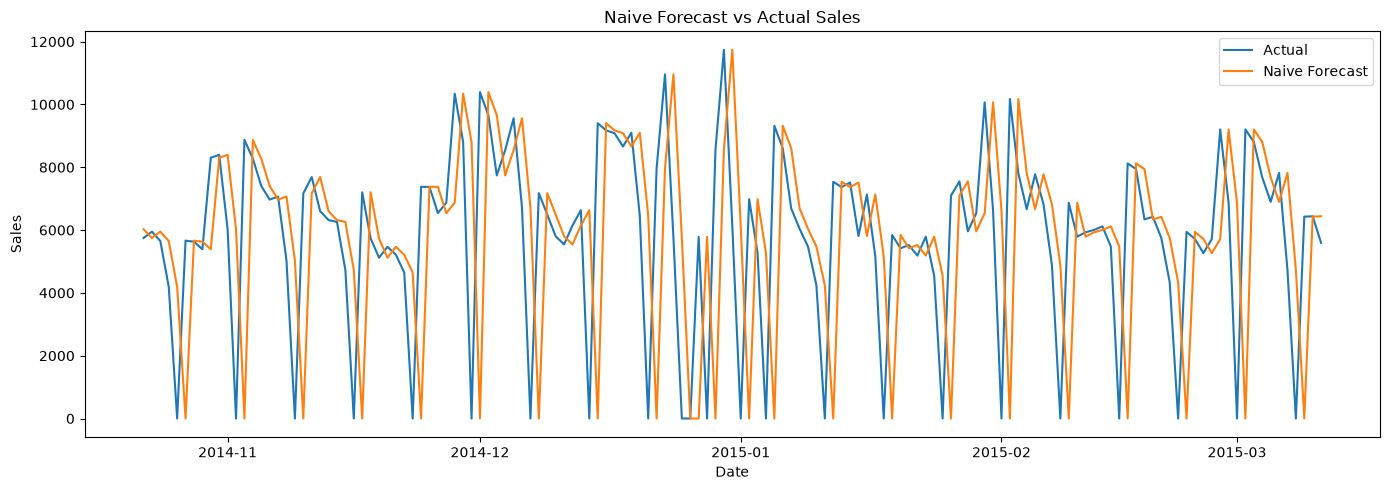

In [128]:
plt.figure(figsize=(14, 5))

plt.plot(
    validation_predictions["Date"],
    validation_predictions["Sales"],
    label="Actual"
)

plt.plot(
    validation_predictions["Date"],
    validation_predictions["Naive_Prediction"],
    label="Naive Forecast"
)

plt.title("Naive Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


In [129]:
forecast_df["Year"] = forecast_df["Date"].dt.year
forecast_df["Month"] = forecast_df["Date"].dt.month
forecast_df["Day"] = forecast_df["Date"].dt.day
forecast_df["DayOfWeek"] = forecast_df["Date"].dt.dayofweek
forecast_df["WeekOfYear"] = forecast_df["Date"].dt.isocalendar().week.astype(int)
forecast_df["Quarter"] = forecast_df["Date"].dt.quarter

In [130]:
forecast_df[
    [
        "Date",
        "Year",
        "Month",
        "Day",
        "DayOfWeek",
        "WeekOfYear",
        "Quarter"
    ]
].head(10)

,Date,Year,Month,Day,DayOfWeek,WeekOfYear,Quarter
0,2013-01-01,2013,1,1,1,1,1
1,2013-01-02,2013,1,2,2,1,1
2,2013-01-03,2013,1,3,3,1,1
3,2013-01-04,2013,1,4,4,1,1
4,2013-01-05,2013,1,5,5,1,1
5,2013-01-06,2013,1,6,6,1,1
6,2013-01-07,2013,1,7,0,2,1
7,2013-01-08,2013,1,8,1,2,1
8,2013-01-09,2013,1,9,2,2,1
9,2013-01-10,2013,1,10,3,2,1


In [131]:
forecast_df["Lag_1"] = (
    forecast_df["Sales"].shift(1)
)

In [132]:
forecast_df["Lag_7"] = (
    forecast_df["Sales"].shift(7)
)

In [133]:
forecast_df["Lag_14"] = (
    forecast_df["Sales"].shift(14)
)

forecast_df["Lag_28"] = (
    forecast_df["Sales"].shift(28)
)

In [135]:
forecast_df["Rolling_Mean_7"] = (
    forecast_df["Sales"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

In [136]:
forecast_df["Rolling_Mean_14"] = (
    forecast_df["Sales"]
    .shift(1)
    .rolling(window=14)
    .mean()
)

In [137]:
forecast_df["Rolling_Mean_30"] = (
    forecast_df["Sales"]
    .shift(1)
    .rolling(window=30)
    .mean()
)

In [138]:
forecast_df[
    [
        "Date",
        "Sales",
        "Promo",
        "StateHoliday",
        "SchoolHoliday",
        "Open"
    ]
].head(10)

,Date,Sales,Promo,StateHoliday,SchoolHoliday,Open
0,2013-01-01,0,0,a,1,0
1,2013-01-02,6576,0,0,1,1
2,2013-01-03,5823,0,0,1,1
3,2013-01-04,5795,0,0,1,1
4,2013-01-05,4885,0,0,0,1
5,2013-01-06,0,0,0,0,0
6,2013-01-07,9237,1,0,0,1
7,2013-01-08,8181,1,0,0,1
8,2013-01-09,6241,1,0,0,1
9,2013-01-10,6439,1,0,0,1


In [139]:
feature_columns = [
    "Date",
    "Sales",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "WeekOfYear",
    "Quarter",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "Open",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_28",
    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_30"
]

model_df = forecast_df[feature_columns].copy()

model_df.head(10)

,Date,Sales,Year,Month,Day,DayOfWeek,WeekOfYear,Quarter,Promo,StateHoliday,SchoolHoliday,Open,Lag_1,Lag_7,Lag_14,Lag_28,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30
0,2013-01-01,0,2013,1,1,1,1,1,0,a,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,6576,2013,1,2,2,1,1,0,0,1,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2013-01-03,5823,2013,1,3,3,1,1,0,0,1,1,6576.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2013-01-04,5795,2013,1,4,4,1,1,0,0,1,1,5823.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2013-01-05,4885,2013,1,5,5,1,1,0,0,0,1,5795.0,NaN,NaN,NaN,NaN,NaN,NaN
5,2013-01-06,0,2013,1,6,6,1,1,0,0,0,0,4885.0,NaN,NaN,NaN,NaN,NaN,NaN
6,2013-01-07,9237,2013,1,7,0,2,1,1,0,0,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
7,2013-01-08,8181,2013,1,8,1,2,1,1,0,0,1,9237.0,0.0,NaN,NaN,4616.571429,NaN,NaN
8,2013-01-09,6241,2013,1,9,2,2,1,1,0,0,1,8181.0,6576.0,NaN,NaN,5785.285714,NaN,NaN
9,2013-01-10,6439,2013,1,10,3,2,1,1,0,0,1,6241.0,5823.0,NaN,NaN,5737.428571,NaN,NaN


In [140]:
model_df.isnull().sum()

Date                0
Sales               0
Year                0
Month               0
Day                 0
DayOfWeek           0
WeekOfYear          0
Quarter             0
Promo               0
StateHoliday        0
SchoolHoliday       0
Open                0
Lag_1               1
Lag_7               7
Lag_14             14
Lag_28             28
Rolling_Mean_7      7
Rolling_Mean_14    14
Rolling_Mean_30    30
dtype: int64

In [141]:
model_df = model_df.dropna().reset_index(drop=True)

In [142]:
model_df.isnull().sum().sum()

np.int64(0)

In [143]:
n = len(model_df)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_model = model_df.iloc[:train_end].copy()
validation_model = model_df.iloc[train_end:validation_end].copy()
test_model = model_df.iloc[validation_end:].copy()

In [144]:
print(
    "Train:",
    train_model["Date"].min(),
    "to",
    train_model["Date"].max()
)

print(
    "Validation:",
    validation_model["Date"].min(),
    "to",
    validation_model["Date"].max()
)

print(
    "Test:",
    test_model["Date"].min(),
    "to",
    test_model["Date"].max()
)

Train: 2013-01-31 00:00:00 to 2014-10-30 00:00:00
Validation: 2014-10-31 00:00:00 to 2015-03-16 00:00:00
Test: 2015-03-17 00:00:00 to 2015-07-31 00:00:00


In [145]:
feature_columns = [
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "WeekOfYear",
    "Quarter",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "Open",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_28",
    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_30"
]

In [146]:
X_train = train_model[feature_columns].copy()
y_train = train_model["Sales"].copy()

X_validation = validation_model[feature_columns].copy()
y_validation = validation_model["Sales"].copy()

X_test = test_model[feature_columns].copy()
y_test = test_model["Sales"].copy()

In [147]:
model_df["StateHoliday"].value_counts()

StateHoliday
0    760
0    129
a     13
b      6
c      4
Name: count, dtype: int64

In [148]:
X_train = pd.get_dummies(
    X_train,
    columns=["StateHoliday"],
    drop_first=True
)

X_validation = pd.get_dummies(
    X_validation,
    columns=["StateHoliday"],
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=["StateHoliday"],
    drop_first=True
)

In [149]:
X_validation = X_validation.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [150]:
print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)
print("Test features:", X_test.shape)

Training features: (638, 20)
Validation features: (137, 20)
Test features: (137, 20)


In [151]:
from sklearn.linear_model import LinearRegression

In [152]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](20,)","[ 92.1 , 281.87, 3.19,...,-2170.56,-2698.63,-1519.94]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['Year','Month','Day',...,'StateHoliday_a','StateHoliday_b', 'StateHoliday_c']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.831e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)


In [153]:
linear_validation_predictions = linear_model.predict(
    X_validation
)

In [154]:
linear_validation_metrics = evaluate_forecast(
    y_validation.values,
    linear_validation_predictions
)

linear_validation_metrics

{'MAE': 744.9230570896011,
 'RMSE': np.float64(1158.45035676308),
 'MAPE': np.float64(11.28990101723887)}

In [155]:
model_results = pd.concat(
    [
        model_results,
        pd.DataFrame([
            {
                "Model": "Linear Regression",
                "MAE": linear_validation_metrics["MAE"],
                "RMSE": linear_validation_metrics["RMSE"],
                "MAPE": linear_validation_metrics["MAPE"]
            }
        ])
    ],
    ignore_index=True
)

model_results

,Model,MAE,RMSE,MAPE
0,Naive,2835.758865,4038.306683,32.604173
1,Linear Regression,744.923057,1158.450357,11.289901


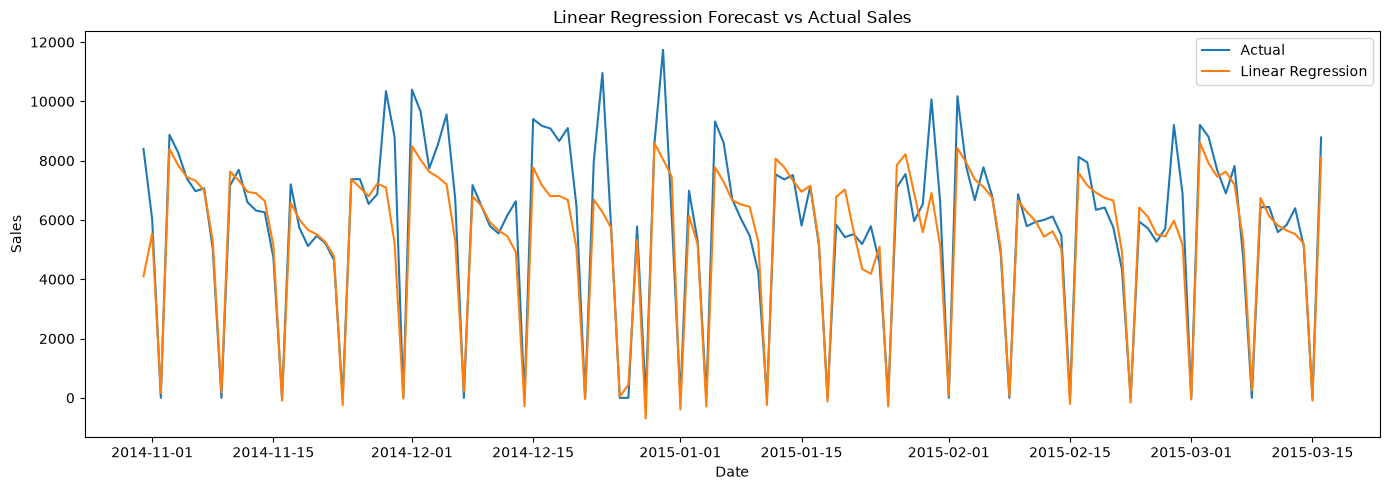

In [156]:
plt.figure(figsize=(14, 5))

plt.plot(
    validation_model["Date"],
    y_validation,
    label="Actual"
)

plt.plot(
    validation_model["Date"],
    linear_validation_predictions,
    label="Linear Regression"
)

plt.title("Linear Regression Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [157]:
from sklearn.ensemble import RandomForestRegressor

In [158]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

In [159]:
rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [161]:
rf_validation_predictions = rf_model.predict(
    X_validation
)

In [162]:
rf_validation_metrics = evaluate_forecast(
    y_validation.values,
    rf_validation_predictions
)

rf_validation_metrics

{'MAE': 557.4968777250763,
 'RMSE': np.float64(910.0853739844134),
 'MAPE': np.float64(9.013600749692479)}

In [163]:
model_results = pd.concat(
    [
        model_results,
        pd.DataFrame([
            {
                "Model": "Random Forest",
                "MAE": rf_validation_metrics["MAE"],
                "RMSE": rf_validation_metrics["RMSE"],
                "MAPE": rf_validation_metrics["MAPE"]
            }
        ])
    ],
    ignore_index=True
)

model_results

,Model,MAE,RMSE,MAPE
0,Naive,2835.758865,4038.306683,32.604173
1,Linear Regression,744.923057,1158.450357,11.289901
2,Random Forest,557.496878,910.085374,9.013601


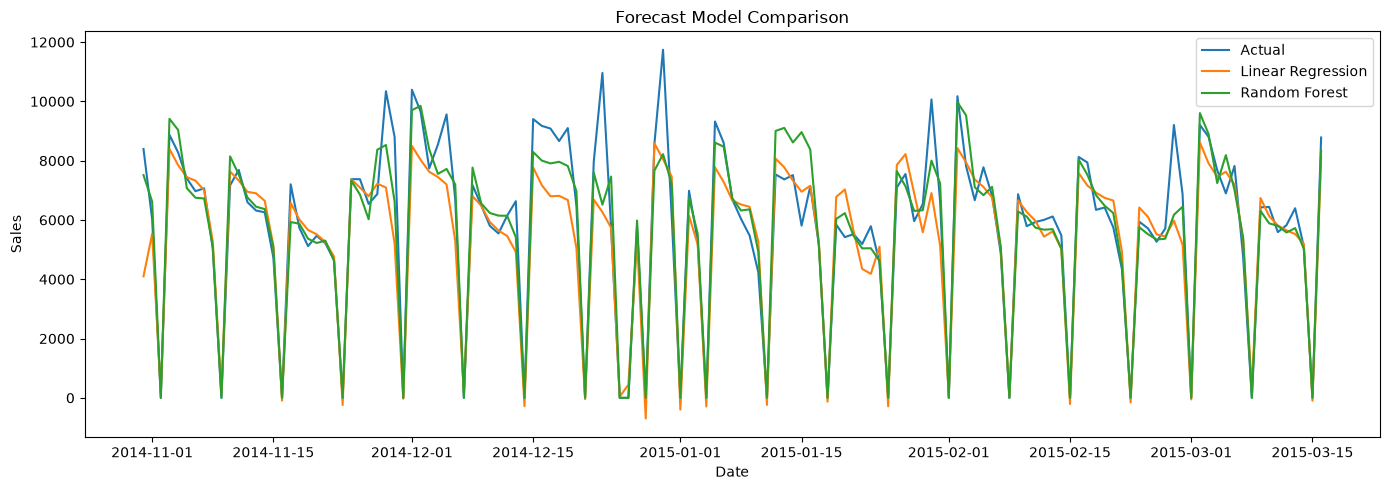

In [164]:
plt.figure(figsize=(14, 5))

plt.plot(
    validation_model["Date"],
    y_validation,
    label="Actual"
)

plt.plot(
    validation_model["Date"],
    linear_validation_predictions,
    label="Linear Regression"
)

plt.plot(
    validation_model["Date"],
    rf_validation_predictions,
    label="Random Forest"
)

plt.title("Forecast Model Comparison")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [165]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importance.head(15)

Open               0.744354
Promo              0.080106
Day                0.054077
Lag_28             0.037421
Lag_1              0.021233
DayOfWeek          0.017302
Rolling_Mean_7     0.013863
Lag_7              0.008605
Rolling_Mean_14    0.007246
Lag_14             0.006639
Rolling_Mean_30    0.003607
WeekOfYear         0.002548
Month              0.001360
Year               0.000666
Quarter            0.000455
dtype: float64

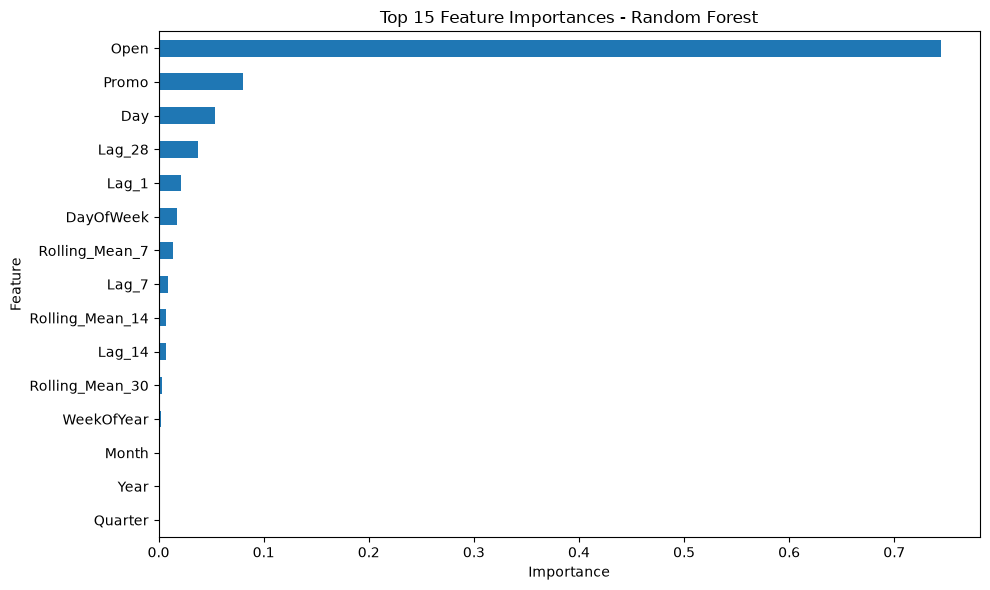

In [166]:
plt.figure(figsize=(10, 6))

feature_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [168]:
rf_train_predictions = rf_model.predict(X_train)

rf_train_metrics = evaluate_forecast(
    y_train.values,
    rf_train_predictions
)

rf_train_metrics

{'MAE': 257.93714759930396,
 'RMSE': np.float64(475.5627882268243),
 'MAPE': np.float64(4.532096246328117)}

In [169]:
print("Training:", rf_train_metrics)
print("Validation:", rf_validation_metrics)

Training: {'MAE': 257.93714759930396, 'RMSE': np.float64(475.5627882268243), 'MAPE': np.float64(4.532096246328117)}
Validation: {'MAE': 557.4968777250763, 'RMSE': np.float64(910.0853739844134), 'MAPE': np.float64(9.013600749692479)}


In [170]:
sarima_df = store_df[
    ["Date", "Sales"]
].copy()

sarima_df = (
    sarima_df
    .set_index("Date")
    .sort_index()
)

sarima_df.head()

,Sales
Date,
2013-01-01,0
2013-01-02,6576
2013-01-03,5823
2013-01-04,5795
2013-01-05,4885


In [171]:
print("Start:", sarima_df.index.min())
print("End:", sarima_df.index.max())
print("Number of observations:", len(sarima_df))

Start: 2013-01-01 00:00:00
End: 2015-07-31 00:00:00
Number of observations: 942


In [172]:
full_date_range = pd.date_range(
    start=sarima_df.index.min(),
    end=sarima_df.index.max(),
    freq="D"
)

missing_dates = full_date_range.difference(
    sarima_df.index
)

print("Missing dates:", len(missing_dates))

Missing dates: 0


In [173]:
n = len(sarima_df)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

sarima_train = sarima_df.iloc[:train_end].copy()

sarima_validation = sarima_df.iloc[
    train_end:validation_end
].copy()

sarima_test = sarima_df.iloc[
    validation_end:
].copy()

In [174]:
print(
    "Train:",
    sarima_train.index.min(),
    "to",
    sarima_train.index.max()
)

print(
    "Validation:",
    sarima_validation.index.min(),
    "to",
    sarima_validation.index.max()
)

print(
    "Test:",
    sarima_test.index.min(),
    "to",
    sarima_test.index.max()
)

Train: 2013-01-01 00:00:00 to 2014-10-21 00:00:00
Validation: 2014-10-22 00:00:00 to 2015-03-11 00:00:00
Test: 2015-03-12 00:00:00 to 2015-07-31 00:00:00


In [175]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [176]:
sarima_model = SARIMAX(
    sarima_train["Sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

c:\Users\radhe\OneDrive\Desktop\Project_5_Rossmann_Sales_Forecasting\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\radhe\OneDrive\Desktop\Project_5_Rossmann_Sales_Forecasting\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [177]:
sarima_fitted = sarima_model.fit(
    disp=False
)

In [178]:
print(sarima_fitted.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             Sales   No. Observations:                  659
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -5678.981
Date:                           Tue, 06 Oct 2026   AIC                          11367.963
Time:                                   00:34:21   BIC                          11390.285
Sample:                               01-01-2013   HQIC                         11376.626
                                    - 10-21-2014                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1994      0.023      8.561      0.000       0.154       0.245
ma.L1         -0.9958      0.011    -90.363

In [179]:
sarima_validation_predictions = (
    sarima_fitted
    .forecast(steps=len(sarima_validation))
)


In [180]:
sarima_validation_metrics = evaluate_forecast(
    sarima_validation["Sales"].values,
    sarima_validation_predictions.values
)

sarima_validation_metrics

{'MAE': 1073.8677398171508,
 'RMSE': np.float64(1644.3034247643086),
 'MAPE': np.float64(14.986548052463045)}

In [181]:
model_results = pd.concat(
    [
        model_results,
        pd.DataFrame([
            {
                "Model": "SARIMA",
                "MAE": sarima_validation_metrics["MAE"],
                "RMSE": sarima_validation_metrics["RMSE"],
                "MAPE": sarima_validation_metrics["MAPE"]
            }
        ])
    ],
    ignore_index=True
)

model_results.sort_values("RMSE")

,Model,MAE,RMSE,MAPE
2,Random Forest,557.496878,910.085374,9.013601
1,Linear Regression,744.923057,1158.450357,11.289901
3,SARIMA,1073.867740,1644.303425,14.986548
0,Naive,2835.758865,4038.306683,32.604173


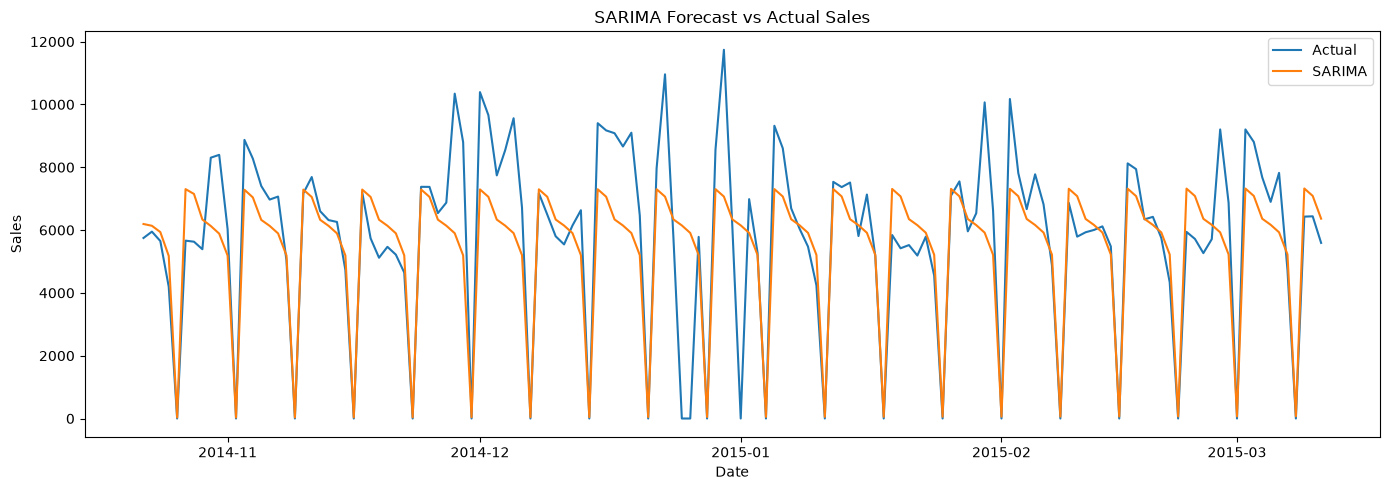

In [182]:
plt.figure(figsize=(14, 5))

plt.plot(
    sarima_validation.index,
    sarima_validation["Sales"],
    label="Actual"
)

plt.plot(
    sarima_validation.index,
    sarima_validation_predictions,
    label="SARIMA"
)

plt.title("SARIMA Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [184]:
model_results = model_results.sort_values(
    by="RMSE"
).reset_index(drop=True)

model_results

,Model,MAE,RMSE,MAPE
0,Random Forest,557.496878,910.085374,9.013601
1,Linear Regression,744.923057,1158.450357,11.289901
2,SARIMA,1073.867740,1644.303425,14.986548
3,Naive,2835.758865,4038.306683,32.604173


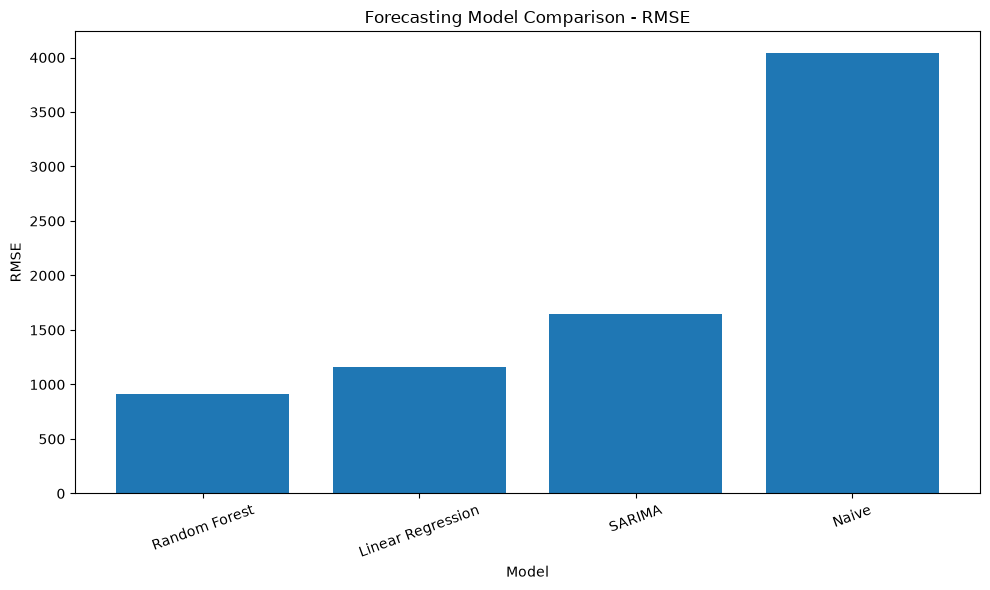

In [185]:
plt.figure(figsize=(10, 6))

plt.bar(
    model_results["Model"],
    model_results["RMSE"]
)

plt.title("Forecasting Model Comparison - RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [186]:
model_results.round(2)

,Model,MAE,RMSE,MAPE
0,Random Forest,557.50,910.09,9.01
1,Linear Regression,744.92,1158.45,11.29
2,SARIMA,1073.87,1644.30,14.99
3,Naive,2835.76,4038.31,32.60


In [187]:
best_model_name = (
    model_results
    .sort_values("RMSE")
    .iloc[0]["Model"]
)

print("Best model based on validation RMSE:", best_model_name)

Best model based on validation RMSE: Random Forest


In [188]:
if best_model_name == "Random Forest":
    test_predictions = rf_model.predict(X_test)

    best_test_metrics = evaluate_forecast(
        y_test.values,
        test_predictions
    )

    print(best_test_metrics)

{'MAE': 494.2876138668429, 'RMSE': np.float64(780.3208147237983), 'MAPE': np.float64(8.288283462221482)}


In [190]:
naive_test_rmse = test_metrics["RMSE"]
best_test_rmse = best_test_metrics["RMSE"]

rmse_improvement = (
    (naive_test_rmse - best_test_rmse)
    / naive_test_rmse
) * 100

print(f"Naive Test RMSE: {naive_test_rmse:.2f}")
print(f"Random Forest Test RMSE: {best_test_rmse:.2f}")
print(f"RMSE improvement over Naive: {rmse_improvement:.2f}%")

Naive Test RMSE: 4200.89
Random Forest Test RMSE: 780.32
RMSE improvement over Naive: 81.42%


In [191]:
print("Best model:", best_model_name)
print("Test metrics:", best_test_metrics)
print(f"RMSE improvement over Naive: {rmse_improvement:.2f}%")

Best model: Random Forest
Test metrics: {'MAE': 494.2876138668429, 'RMSE': np.float64(780.3208147237983), 'MAPE': np.float64(8.288283462221482)}
RMSE improvement over Naive: 81.42%


In [196]:
forecast_horizon = 30

last_date = forecast_df["Date"].max()

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=forecast_horizon,
    freq="D"
)

print("Forecast start:", future_dates.min())
print("Forecast end:", future_dates.max())

Forecast start: 2015-08-01 00:00:00
Forecast end: 2015-08-30 00:00:00


In [199]:
history = forecast_df[
    [
        "Date",
        "Sales",
        "Promo",
        "StateHoliday",
        "SchoolHoliday",
        "Open"
    ]
].copy()

history = history.sort_values("Date").reset_index(drop=True)

future_predictions = []

for future_date in future_dates:

    current_index = len(history)

    # Assume normal future operating conditions
    future_row = {
        "Date": future_date,
        "Sales": np.nan,
        "Promo": 0,
        "StateHoliday": "0",
        "SchoolHoliday": 0,
        "Open": 1
    }

    history = pd.concat(
        [
            history,
            pd.DataFrame([future_row])
        ],
        ignore_index=True
    )

    sales_history = history["Sales"]

    prediction_row = pd.DataFrame([{
        "Year": future_date.year,
        "Month": future_date.month,
        "Day": future_date.day,
        "DayOfWeek": future_date.dayofweek,
        "WeekOfYear": int(future_date.isocalendar().week),
        "Quarter": future_date.quarter,
        "Promo": 0,
        "StateHoliday": "0",
        "SchoolHoliday": 0,
        "Open": 1,
        "Lag_1": sales_history.iloc[current_index - 1],
        "Lag_7": sales_history.iloc[current_index - 7],
        "Lag_14": sales_history.iloc[current_index - 14],
        "Lag_28": sales_history.iloc[current_index - 28],
        "Rolling_Mean_7": sales_history.iloc[:current_index].tail(7).mean(),
        "Rolling_Mean_14": sales_history.iloc[:current_index].tail(14).mean(),
        "Rolling_Mean_30": sales_history.iloc[:current_index].tail(30).mean()
    }])

    prediction_row = pd.get_dummies(
        prediction_row,
        columns=["StateHoliday"],
        drop_first=True
    )

    prediction_row = prediction_row.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    prediction = rf_model.predict(prediction_row)[0]

    prediction = max(0, prediction)

    history.loc[current_index, "Sales"] = prediction

    future_predictions.append(prediction)

print("Forecasts generated:", len(future_predictions))

Forecasts generated: 30


In [201]:
future_forecast = pd.DataFrame({
    "Date": future_dates,
    "Forecasted_Sales": future_predictions
})

future_forecast.head()

,Date,Forecasted_Sales
0,2015-08-01,6578.164493
1,2015-08-02,5134.801947
2,2015-08-03,6025.506250
3,2015-08-04,5933.263771
4,2015-08-05,5783.612539


In [202]:
future_forecast

,Date,Forecasted_Sales
0,2015-08-01,6578.164493
1,2015-08-02,5134.801947
2,2015-08-03,6025.506250
3,2015-08-04,5933.263771
4,2015-08-05,5783.612539
5,2015-08-06,5807.231069
6,2015-08-07,6101.930693
7,2015-08-08,5018.755686
8,2015-08-09,4812.015721
9,2015-08-10,5779.059930


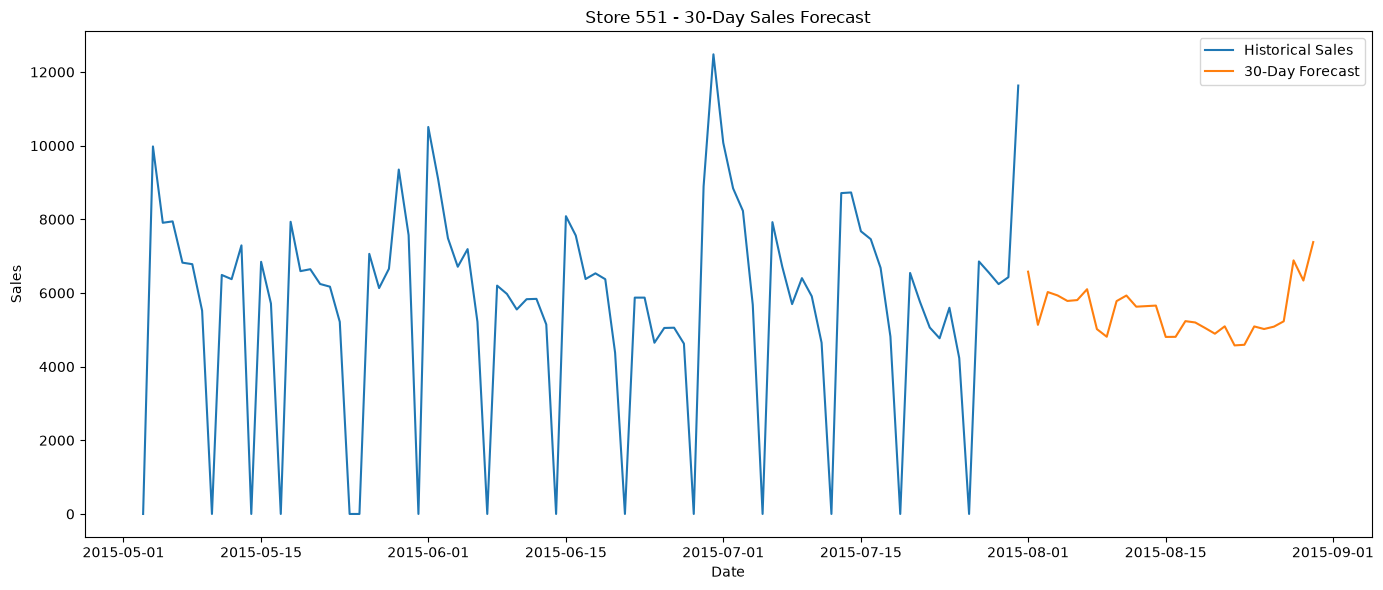

In [203]:
plt.figure(figsize=(14, 6))

recent_history = forecast_df.tail(90)

plt.plot(
    recent_history["Date"],
    recent_history["Sales"],
    label="Historical Sales"
)

plt.plot(
    future_forecast["Date"],
    future_forecast["Forecasted_Sales"],
    label="30-Day Forecast"
)

plt.title(
    f"Store {candidate_store} - 30-Day Sales Forecast"
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [205]:
total_forecast_sales = future_forecast["Forecasted_Sales"].sum()

print(
    f"Expected sales over next 30 days: "
    f"{total_forecast_sales:,.0f}"
)

Expected sales over next 30 days: 165,129


In [206]:
top_forecast_days = (
    future_forecast
    .sort_values(
        "Forecasted_Sales",
        ascending=False
    )
    .head(5)
)

top_forecast_days

,Date,Forecasted_Sales
29,2015-08-30,7382.728070
27,2015-08-28,6885.308576
0,2015-08-01,6578.164493
28,2015-08-29,6337.645753
6,2015-08-07,6101.930693


In [207]:
lowest_forecast_days = (
    future_forecast
    .sort_values(
        "Forecasted_Sales",
        ascending=True
    )
    .head(5)
)

lowest_forecast_days

,Date,Forecasted_Sales
21,2015-08-22,4576.633497
22,2015-08-23,4593.631616
14,2015-08-15,4806.643629
15,2015-08-16,4809.515189
8,2015-08-09,4812.015721


In [208]:
midpoint = len(future_forecast) // 2

first_half_average = (
    future_forecast
    .iloc[:midpoint]["Forecasted_Sales"]
    .mean()
)

second_half_average = (
    future_forecast
    .iloc[midpoint:]["Forecasted_Sales"]
    .mean()
)

print(
    f"First half average: {first_half_average:,.0f}"
)

print(
    f"Second half average: {second_half_average:,.0f}"
)

First half average: 5,643
Second half average: 5,366


In [210]:
forecast_trend_change = (
    (second_half_average - first_half_average)
    / first_half_average
) * 100

print(
    f"Forecast change: {forecast_trend_change:.2f}%"
)

Forecast change: -4.91%


In [211]:
future_forecast["Day_Name"] = (
    future_forecast["Date"].dt.day_name()
)

forecast_weekday_pattern = (
    future_forecast
    .groupby("Day_Name")["Forecasted_Sales"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

forecast_weekday_pattern

Day_Name
Monday       5532.908402
Tuesday      5521.249363
Wednesday    5386.775171
Thursday     5393.792213
Friday       5934.862965
Saturday     5463.568612
Sunday       5346.538509
Name: Forecasted_Sales, dtype: float64

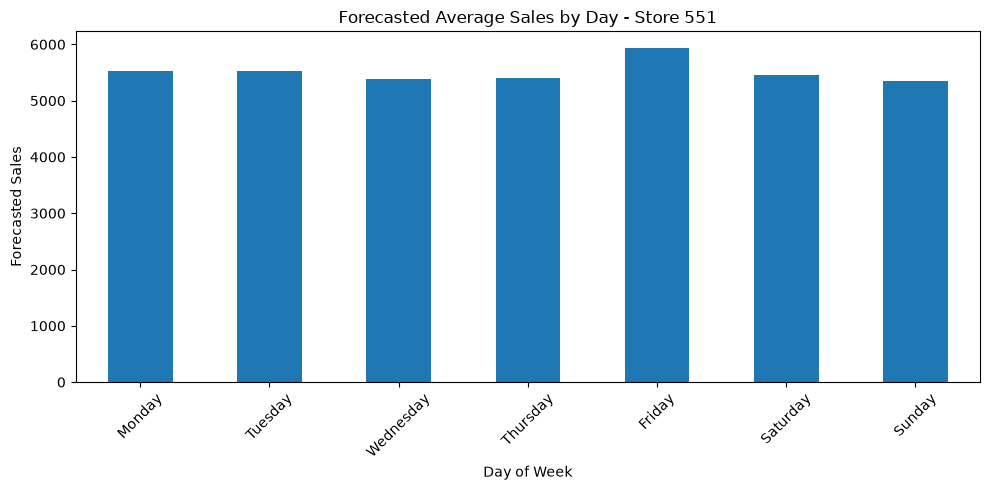

In [212]:
plt.figure(figsize=(10, 5))

forecast_weekday_pattern.plot(
    kind="bar"
)

plt.title(
    f"Forecasted Average Sales by Day - Store {candidate_store}"
)

plt.xlabel("Day of Week")
plt.ylabel("Forecasted Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [213]:
recent_average_sales = (
    forecast_df
    .tail(30)["Sales"]
    .mean()
)

forecast_average_sales = (
    future_forecast["Forecasted_Sales"]
    .mean()
)

comparison = pd.DataFrame({
    "Period": [
        "Last 30 Days",
        "Next 30 Days"
    ],
    "Average_Daily_Sales": [
        recent_average_sales,
        forecast_average_sales
    ]
})

comparison

,Period,Average_Daily_Sales
0,Last 30 Days,5793.566667
1,Next 30 Days,5504.296269


In [214]:
expected_change = (
    (forecast_average_sales - recent_average_sales)
    / recent_average_sales
) * 100

print(
    f"Expected change in average daily sales: "
    f"{expected_change:.2f}%"
)

Expected change in average daily sales: -4.99%


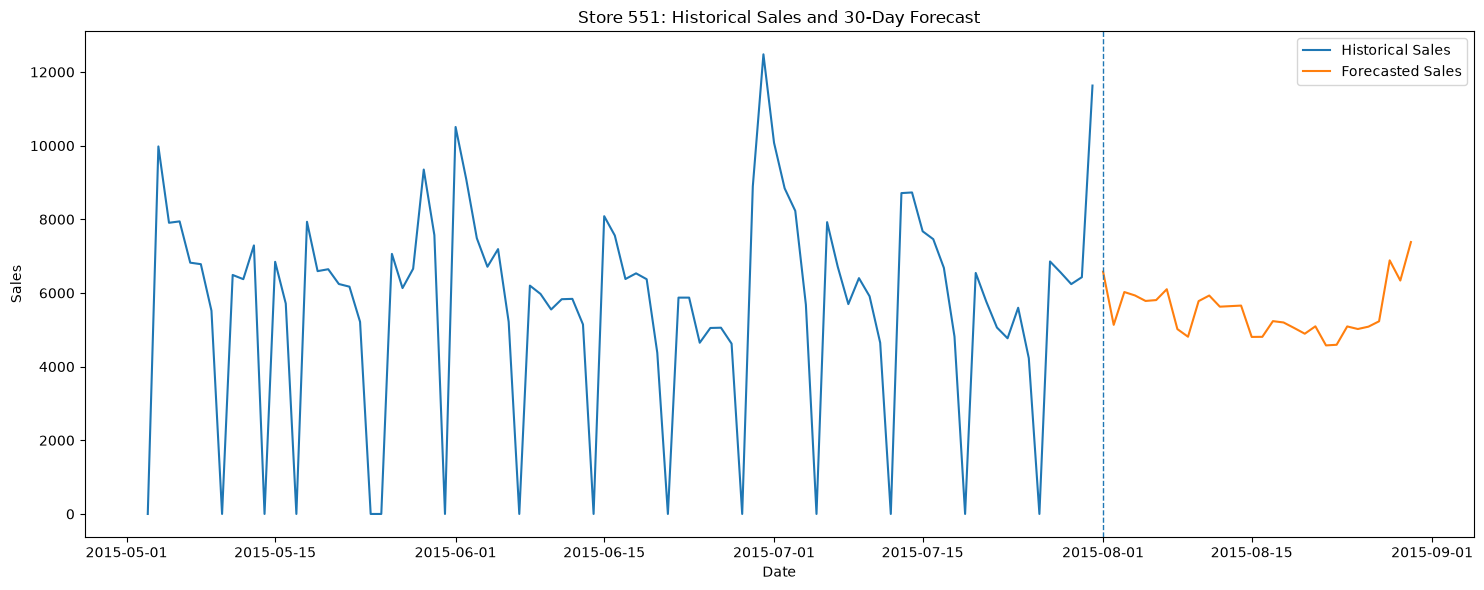

In [215]:
plt.figure(figsize=(15, 6))

recent_history = forecast_df.tail(90)

plt.plot(
    recent_history["Date"],
    recent_history["Sales"],
    label="Historical Sales"
)

plt.plot(
    future_forecast["Date"],
    future_forecast["Forecasted_Sales"],
    label="Forecasted Sales"
)

plt.axvline(
    future_forecast["Date"].iloc[0],
    linestyle="--",
    linewidth=1
)

plt.title(
    f"Store {candidate_store}: Historical Sales and 30-Day Forecast"
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [216]:
future_forecast.to_csv(
    "../outputs/store_forecast_30_days.csv",
    index=False
)

print("Forecast saved successfully.")

Forecast saved successfully.


In [218]:
average_forecast_sales = future_forecast["Forecasted_Sales"].mean()

recent_average_sales = forecast_df.tail(30)["Sales"].mean()

expected_change = (
    (average_forecast_sales - recent_average_sales)
    / recent_average_sales
) * 100

print(f"Average Daily Forecast: {average_forecast_sales:,.0f}")
print(f"Expected Change vs Recent 30 Days: {expected_change:.2f}%")

Average Daily Forecast: 5,504
Expected Change vs Recent 30 Days: -4.99%


In [219]:
print("===== BUSINESS FORECAST SUMMARY =====")
print()
print(f"Store: {candidate_store}")
print(f"Forecast Horizon: 30 days")
print(f"Total Forecasted Sales: {total_forecast_sales:,.0f}")
print(f"Average Daily Forecast: {average_forecast_sales:,.0f}")
print(f"Expected Change vs Recent 30 Days: {expected_change:.2f}%")
print()
print("Highest Forecasted Sales Days:")
print(top_forecast_days[["Date", "Forecasted_Sales"]])
print()
print("Lowest Forecasted Sales Days:")
print(lowest_forecast_days[["Date", "Forecasted_Sales"]])

===== BUSINESS FORECAST SUMMARY =====

Store: 551
Forecast Horizon: 30 days
Total Forecasted Sales: 165,129
Average Daily Forecast: 5,504
Expected Change vs Recent 30 Days: -4.99%

Highest Forecasted Sales Days:
         Date  Forecasted_Sales
29 2015-08-30       7382.728070
27 2015-08-28       6885.308576
0  2015-08-01       6578.164493
28 2015-08-29       6337.645753
6  2015-08-07       6101.930693

Lowest Forecasted Sales Days:
         Date  Forecasted_Sales
21 2015-08-22       4576.633497
22 2015-08-23       4593.631616
14 2015-08-15       4806.643629
15 2015-08-16       4809.515189
8  2015-08-09       4812.015721


In [224]:
model_comparison = model_results.sort_values("RMSE").reset_index(drop=True)

model_comparison

,Model,MAE,RMSE,MAPE
0,Random Forest,557.496878,910.085374,9.013601
1,Linear Regression,744.923057,1158.450357,11.289901
2,SARIMA,1073.867740,1644.303425,14.986548
3,Naive,2835.758865,4038.306683,32.604173


In [225]:
for model_name, metrics in model_results.items():
    print(model_name)
    print(metrics)
    print()

Model
0        Random Forest
1    Linear Regression
2               SARIMA
3                Naive
Name: Model, dtype: str

MAE
0     557.496878
1     744.923057
2    1073.867740
3    2835.758865
Name: MAE, dtype: float64

RMSE
0     910.085374
1    1158.450357
2    1644.303425
3    4038.306683
Name: RMSE, dtype: float64

MAPE
0     9.013601
1    11.289901
2    14.986548
3    32.604173
Name: MAPE, dtype: float64



In [226]:
model_comparison.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [227]:
future_forecast.to_csv(
    "../outputs/store_forecast_30_days.csv",
    index=False
)

print("Forecast saved successfully.")
print(f"Forecast rows: {len(future_forecast)}")

Forecast saved successfully.
Forecast rows: 30
